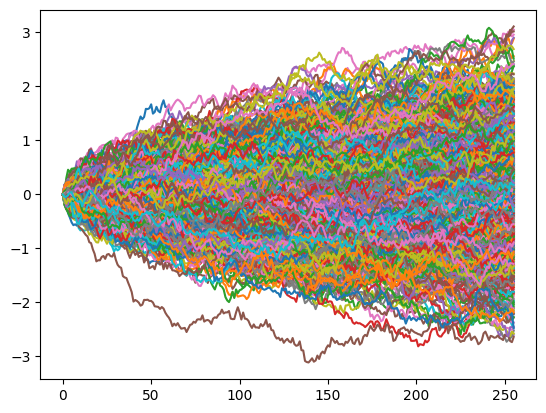

In [7]:
import numpy as np
import matplotlib.pyplot as plt

T=1
N=255
dt=T/N
M=1000

S0=100
K=110
mu=0.15
sigma=0.2
r=0.05

#construction mouvement brownien par somme cummulative 
dW= np.sqrt(dt)*np.random.randn(N,M)
W= np.zeros((N+1,M))
W[0,:]=0
W[1:,:]=np.cumsum(dW,axis=0)

t=np.linspace(0,T,N+1,endpoint=True)
#plot
plt.figure('brownian')
plt.plot(W)
plt.show()

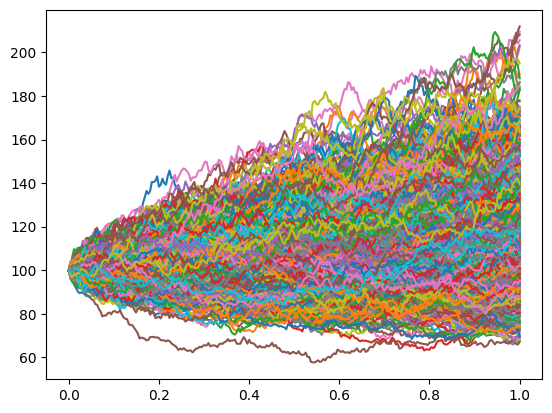

In [8]:
# construction du processus de prix S: dS/S = mu*dt + sigma* dWt
S= S0*np.exp( (mu-sigma**2/2)*t[:,None] + sigma*W)
#plot
plt.plot(t,S)

S_risque_neutre= S0*np.exp( (r-sigma**2/2)*t[:,None] + sigma*W)
prix_option= np.exp(-r*T)*np.mean(
    
    np.maximum(S_risque_neutre[-1,:]-K,0))

plt.show()

In [9]:
for M in 100000 * np.arange(1,6): 
    T=1
    N = 250
    dt=T/N

    S0=100
    K=110
    mu=0.15
    sigma=0.2
    r=0.05

    #construction mouvement brownien par somme cummulative 
    dW= np.sqrt(dt)*np.random.randn(N,M)
    W= np.zeros((N+1,M))
    W[0,:]=0
    W[1:,:]=np.cumsum(dW,axis=0)

    # Time grid must match W: N + 1 time points
    t = np.linspace(0, T, N + 1)

    S = S0 * np.exp(
        (mu - sigma**2 / 2) * t[:, None] + sigma * W
    )

    S_risque_neutre= S0*np.exp( (r-sigma**2/2)*t[:,None] + sigma*W)
    prix_option= np.exp(-r*T)*np.mean(
        np.maximum(S_risque_neutre[-1,:]-K,0))

    print(f"Prix de l'option call par simulation Monte Carlo pour M={M}: {prix_option}")

Prix de l'option call par simulation Monte Carlo pour M=100000: 6.028290743038304
Prix de l'option call par simulation Monte Carlo pour M=200000: 6.043268431889881
Prix de l'option call par simulation Monte Carlo pour M=300000: 6.0645025451669285
Prix de l'option call par simulation Monte Carlo pour M=400000: 6.048364629414764
Prix de l'option call par simulation Monte Carlo pour M=500000: 6.019291464335517


# -*- coding: utf-8 -*-
"""
# Delta Hedging Implementation Exercise
This exercise implements delta hedging to maintain a delta-neutral portfolio and simulate its performance.

(c) Gabriel Turinici 2025

### Key Variables and Their Significance
- **Stock Price (S):** Simulated paths of the stock price using Geometric Brownian Motion.
- **Delta (delta):** Represents the sensitivity of the option price to stock price changes.
- **Cash Balance (cash):** Tracks portfolio cash after hedging adjustments.
- **Transaction Costs (f):** Costs incurred while adjusting the hedge.

### Initial Position Setup
At the start of the simulation:
- The option is purchased at its initial price, \( option\_price\_0 \).
- The portfolio begins with a cash balance equal to \( option\_price\_0 - delta\_0 \times S_0 \), where \( delta\_0 \) is the initial delta, and \( S_0 \) is the initial stock price.
- The portfolio holds \( delta\_0 \) shares of the stock to hedge the option's exposure to changes in \( S_0 \).

### Explanation of the For Loop
The **for** loop iterates over the time steps of the simulation. Its purpose is to dynamically adjust the portfolio's holdings to maintain a delta-neutral position as the stock price changes. Here's what happens at each iteration:

1. **Risk-Free Growth of Cash:**
   The cash balance grows at the risk-free interest rate \( r \) over the time step \( dt \). This accounts for the fact that the uninvested cash in the portfolio earns interest.

2. **Recalculation of Delta:**
   The delta is recalculated at each time step based on the current stock price, remaining time to maturity, and option parameters. This updated delta reflects the new sensitivity of the option value to changes in the stock price.

3. **Adjusting for Delta Changes:**
   - The portfolio adjusts its holdings of the stock to match the new delta. If the delta increases, additional shares are purchased; if it decreases, shares are sold.
   - The cost of this adjustment is subtracted from the cash balance. Transaction costs, proportional to the number of shares bought or sold, are also deducted from the cash.

4. **Updating Delta:**
   After the adjustments, the new delta becomes the current delta for the next iteration.

### Final Adjustments at Maturity
At the end of the simulation (maturity):
1. **Option Payoff:**
   The option payoff is subtracted from the cash balance. For a call option, the payoff is \( \max(S_T - K, 0) \), where \( S_T \) is the stock price at maturity and \( K \) is the strike price.

2. **Liquidating Stock Holdings:**
   Any remaining shares in the portfolio are sold at the maturity stock price \( S_T \), and the proceeds are added to the cash balance.

### Summary of Implementation Steps
- **Initial Setup:** Compute the initial option price and delta, and initialize the cash balance.
- **Iterative Adjustments:** Use the for loop to update the cash balance, adjust the stock holdings, and account for transaction costs at each time step.
- **Final Adjustments:** Compute the option payoff and liquidate the remaining stock holdings to determine the final portfolio value.

This iterative process ensures that the portfolio remains delta-neutral throughout the option's lifetime, minimizing the risk associated with changes in the stock price.


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

def blsprice(Price, Strike, Rate, TimeToMaturity, Volatility, DividendRate=0):
    if TimeToMaturity <= 1e-6:
        call = np.maximum(Price - Strike, 0)
        put = np.maximum(Strike - Price, 0)
        return call, put

    d1 = (np.log(Price / Strike) + (Rate - DividendRate + 0.5 * Volatility**2) * TimeToMaturity) / (Volatility * np.sqrt(TimeToMaturity))
    d2 = d1 - Volatility * np.sqrt(TimeToMaturity)
    call = Price * np.exp(-DividendRate * TimeToMaturity) * norm.cdf(d1) - Strike * np.exp(-Rate * TimeToMaturity) * norm.cdf(d2)
    put = Strike * np.exp(-Rate * TimeToMaturity) * norm.cdf(-d2) - Price * np.exp(-DividendRate * TimeToMaturity) * norm.cdf(-d1)
    return call, put

#test: blsprice(100,110,0.05,1,0.2)
#blsprice(np.array([100,101]),np.array([110,111]),0.05,1,0.2)

def blsdelta(Price,Strike,Rate,TimeToMaturity,Volatility,DividendRate=0):
    """input:
       S:Price - Current price of the underlying asset.

       Strike:Strike - Strike (i.e., exercise) price of the option.

       Rate: Rate - Annualized continuously compounded risk-free rate of return over
         the life of the option, expressed as a positive decimal number.

       TimeToMaturity:Time - Time to expiration of the option, expressed in years.

      Volatility: volatility
      DividendRate = continuous dividend rate
    """

    if TimeToMaturity <= 1e-6: # the option already expired
        call = (Price>=Strike).astype(float) # 1 if in the money, zero otherwise
        put = (Price<=Strike).astype(float) # cf above
        return call,put


    d1 = np.log(Price/Strike)+(Rate-DividendRate + Volatility**2/2.0)*TimeToMaturity;
    d1 = d1/(Volatility* np.sqrt(TimeToMaturity))

    call =  np.exp(-DividendRate*TimeToMaturity) * norm.cdf(d1)
    put  = -np.exp(-DividendRate*TimeToMaturity) * norm.cdf(-d1)
    return call,put

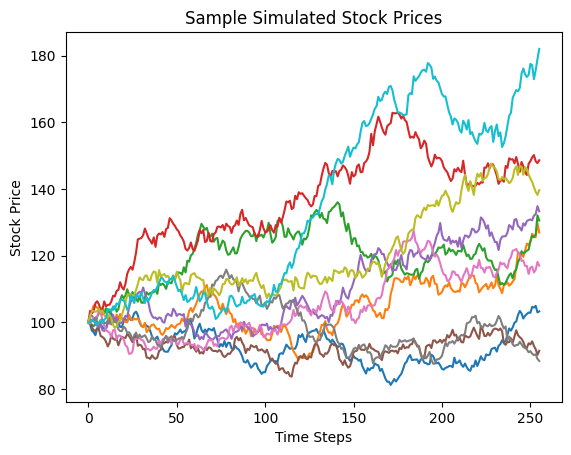

In [13]:
T = 1  # Maturity time in years
N = 255  # Number of time steps
dt = T / N
M = 1000  # Number of simulations

S0 = 100
K = 110
mu = 0.15
sigma = 0.2
r = 0.05
f = 0.00

"""### Stock Price Simulation
Using Geometric Brownian Motion (GBM), simulate the stock price paths.
"""

dW = np.sqrt(dt) * np.random.randn(N, M)
W = np.zeros((N + 1, M))
W[1:, :] = np.cumsum(dW, axis=0)

t = np.linspace(0, T, N + 1)
S = S0 * np.exp((mu - 0.5 * sigma**2) * t[:, None] + sigma * W)
price = np.exp(-r*T)*np.mean(
    np.maximum(S[-1,:]-K,0))

plt.plot(S[:, :10])
plt.title("Sample Simulated Stock Prices")
plt.xlabel("Time Steps")
plt.ylabel("Stock Price")
plt.show()

In [ ]:
"""### Initial Portfolio Setup
Compute the initial option price, delta, and cash balance.
"""

cash = np.zeros_like(S)
delta=np.zeros((N+1,M))
initial_price = blsprice(S[0,:], K, r, T, sigma, DividendRate=0)[0]
delta[0,:]  = blsdelta(S[0,:], K, r, T, sigma, DividendRate=0)[0]#calcul of initial delta
cash[0, :]  = initial_price  # We add to the cash the initial price of the option
cash[0, :] -= delta[0,:]*S[0,:]  # substract from the cash the initial price of buying the hedging position

"""### Delta Hedging Loop
Iteratively adjust the portfolio to remain delta-neutral.
"""

for jj in range(N):
    cash[jj + 1, :] = cash[jj, :] * np.exp(r * dt)  # Update cash with risk-free rate
    delta[jj + 1,:] = blsdelta(S[jj + 1,:], K, r, T - t[jj + 1], sigma, DividendRate=0)[0]  # Compute new delta based on current stock price
    cash[jj + 1, :] -= delta[jj + 1,:]*S[jj + 1,:]  # Adjust cash for delta change cost
    cash[jj + 1, :] -= f * np.abs(delta[jj + 1,:]) * S[jj + 1,:]  # Account for transaction costs

"""### Final Adjustments at Maturity
At the option's maturity, compute the payoff and liquidate remaining holdings.
"""

cash[-1, :] -= np.maximum(S[-1,:]-K,0) # Deduct option payoff
cash[-1, :] += delta[-1,:]*S[-1,:]  # Liquidate remaining shares

"""### Final Portfolio Value Distribution
Plot the histogram of the final portfolio values.
"""

plt.hist(cash[-1, :]*100/initial_price, bins=50)
plt.title("Distribution of Final Portfolio Value")
plt.xlabel("Portfolio Value")
plt.ylabel("Frequency")
plt.show()

TypeError: '<=' not supported between instances of 'NoneType' and 'float'